# ✈️ Google Flights Airfare Forecast

Predicting airline ticket prices and building a **best day to book** calendar — given a route, airline, fare class and departure date, it tells you when to book over the next 7 days and how much you save versus booking today.

In [1]:
#@title Setup
from datetime import datetime, timedelta
from warnings import filterwarnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_selection import RFE, SelectKBest, f_regression
from sklearn.preprocessing import LabelEncoder

import xgboost as xgb
from sklearn.model_selection import ParameterSampler
from sklearn.metrics import mean_absolute_percentage_error

# Ignore warnings
filterwarnings('ignore')

# Set seed
SEED = 123
np.random.seed(SEED)
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

# Chart styling: one fixed categorical order (blue, orange, aqua), recessive grid
C1, C2, C3 = '#2a78d6', '#eb6834', '#1baf7a'
INK, INK2, GRID = '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({
    'figure.figsize': (10, 4.5), 'figure.dpi': 110,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': INK2, 'axes.labelcolor': INK2, 'axes.titlecolor': INK,
    'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'xtick.color': INK2, 'ytick.color': INK2, 'lines.linewidth': 2,
    'axes.prop_cycle': plt.cycler(color=[C1, C2, C3]),
})
FARE_COLORS = {'Economy': C1, 'Business': C2, 'First': C3}

## Problem Definition

Google Flights users want to know: *when is the best time to book?*

I built two things to answer that:

1. **A price model** — predicts ticket price given the booking date, route, airline, fare class and departure date.
2. **A scenario tool** — runs the model over a 7-day booking window, finds the cheapest day and shows the saving vs. booking today.

In [2]:
# Load data
df_booking = pd.read_csv("data/google_flights_airfare_data.csv")
df_booking.head()

,transaction_id,flight_id,airline,origin,destination,booking_dt,departure_dt,price,fare_class
0,898b2db0d,ced9a2,American Airlines,ORD,BOS,2024-04-02 14:00:10,2024-07-09 07:47:00,327.15,Economy
1,5b8144206,ced9a2,American Airlines,ORD,BOS,2024-05-19 08:44:17,2024-07-09 07:47:00,191.25,Economy
2,2e458f769,ced9a2,American Airlines,ORD,BOS,2024-02-23 22:11:51,2024-07-09 07:47:00,579.79,Economy
3,2c9e3e129,ced9a2,American Airlines,ORD,BOS,2024-04-22 23:43:37,2024-07-09 07:47:00,579.06,Economy
4,9de7ad563,ced9a2,American Airlines,ORD,BOS,2024-04-28 17:55:53,2024-07-09 07:47:00,207.06,Economy


## Exploratory Data Analysis

## Overview

In [3]:
print(f"Rows: {len(df_booking):,}   Columns: {df_booking.shape[1]}")
print(f"Unique flights: {df_booking.flight_id.nunique():,}   Unique transactions: {df_booking.transaction_id.nunique():,}")
for col in ['airline', 'origin', 'destination', 'fare_class']:
    print(f"{col:12s}: {sorted(df_booking[col].unique())}")
print(f"Booking dates:   {df_booking.booking_dt.min()}  to  {df_booking.booking_dt.max()}")
print(f"Departure dates: {df_booking.departure_dt.min()}  to  {df_booking.departure_dt.max()}")
df_booking.describe(include='all').T

Rows: 225,209   Columns: 9
Unique flights: 2,189   Unique transactions: 225,208
airline     : ['American Airlines', 'Delta Air Lines', 'United Airlines']
origin      : ['ATL', 'JFK', 'LAX', 'ORD', 'SFO']
destination : ['BOS', 'DEN', 'DFW', 'MIA', 'SEA']
fare_class  : ['Business', 'Economy', 'First']
Booking dates:   2021-10-12 11:58:26  to  2024-09-12 14:58:34
Departure dates: 2022-04-09 04:12:00  to  2024-09-15 06:11:00


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
transaction_id,225209,225208,0f929f480,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
flight_id,225209,2189,cf9731,199,NaN,NaN,NaN,NaN,NaN,NaN,NaN
airline,225209,3,American Airlines,75915,NaN,NaN,NaN,NaN,NaN,NaN,NaN
origin,225209,5,SFO,45748,NaN,NaN,NaN,NaN,NaN,NaN,NaN
destination,225209,5,DFW,46911,NaN,NaN,NaN,NaN,NaN,NaN,NaN
booking_dt,225209,224815,2023-07-20 06:41:09,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
departure_dt,225209,2186,2022-11-23 12:34:00,218,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price,"225,209.00",NaN,NaN,NaN,509.67,385.89,16.61,245.29,417.28,654.30,"6,639.68"
fare_class,225209,3,Economy,179867,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Takeaways**

- About 225k bookings on 2,189 flights, each flight sold in Economy, Business and First (roughly 100 bookings per flight).
- 3 airlines, 5 origins (ATL, JFK, LAX, ORD, SFO) and 5 destinations (BOS, DEN, DFW, MIA, SEA), so 25 routes. Note the boilerplate's example route JFK to LAX does not exist in this data; LAX is only an origin.
- Departures run from April 2022 to September 2024 and bookings are made 1 to 179 days ahead.

## Missingness

In [4]:
miss = pd.DataFrame({'missing': df_booking.isna().sum(), 'pct': df_booking.isna().mean() * 100})
print(miss)
print("\nFully duplicated rows:", df_booking.duplicated().sum())
print("Duplicated transaction_id:", df_booking.transaction_id.duplicated().sum())
print("Non-positive prices:", (df_booking.price <= 0).sum())
print("Origin == destination:", (df_booking.origin == df_booking.destination).sum())
print("Booking after departure:", (pd.to_datetime(df_booking.booking_dt) >= pd.to_datetime(df_booking.departure_dt)).sum())
ids = df_booking.groupby('flight_id')[['origin', 'destination', 'departure_dt']].nunique()
print("flight_ids reused for more than one route/departure:", (ids.max(axis=1) > 1).sum())

                missing  pct
transaction_id        0 0.00
flight_id             0 0.00
airline               0 0.00
origin                0 0.00
destination           0 0.00
booking_dt            0 0.00
departure_dt          0 0.00
price                 0 0.00
fare_class            0 0.00



Fully duplicated rows: 0
Duplicated transaction_id: 1
Non-positive prices: 0
Origin == destination: 0
Booking after departure: 0
flight_ids reused for more than one route/departure: 1


**Data quality**

- No missing values, no impossible prices, and every booking happens before departure.
- One `transaction_id` appears twice (with different content) and one `flight_id` is reused across two flights. Both are tiny and harmless for a price model, which never uses the IDs as features, so we keep the rows.
- A bigger oddity shows up in the target analysis below: **Business fares are about half of Economy fares**. That is the reverse of the real world and looks like a labelling quirk in the simulation. We keep the data as-is (the model just learns the pattern), but it should be raised with the data owner before any real launch.

## Univariate Analysis

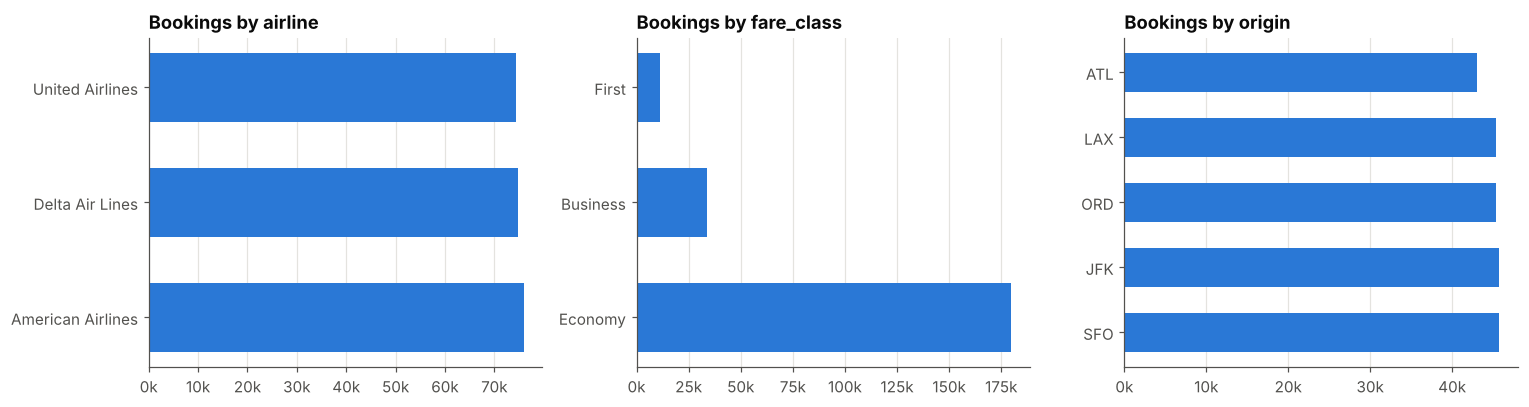

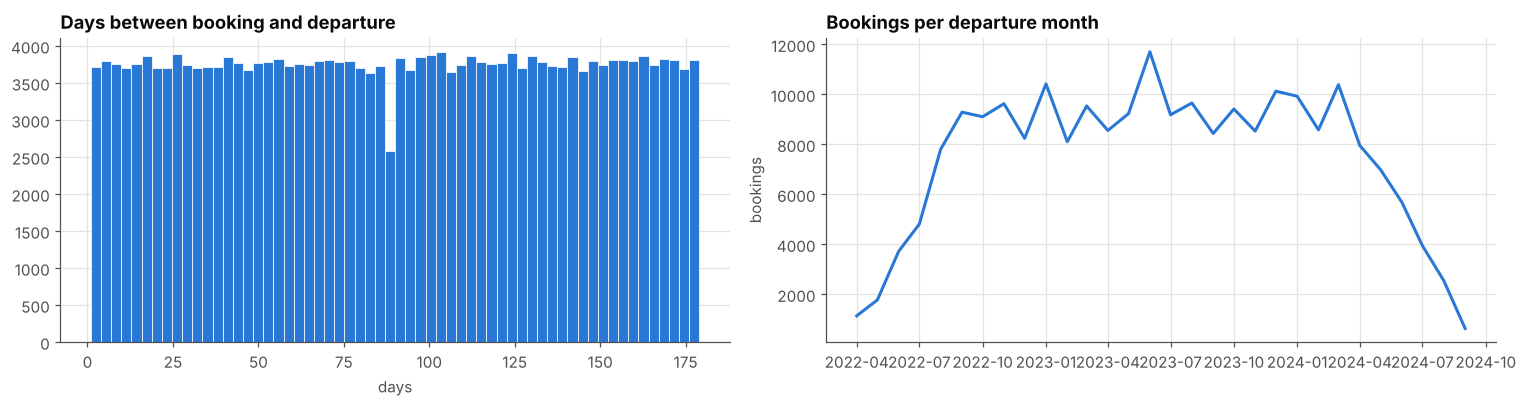

In [5]:
d = df_booking.copy()
d['booking_dt'] = pd.to_datetime(d.booking_dt); d['departure_dt'] = pd.to_datetime(d.departure_dt)
d['days_before'] = (d.departure_dt - d.booking_dt).dt.days

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, col in zip(axes, ['airline', 'fare_class', 'origin']):
    vc = d[col].value_counts()
    ax.barh(vc.index, vc.values, color=C1, height=0.6)
    ax.set_title(f'Bookings by {col}'); ax.grid(axis='y', visible=False)
    ax.xaxis.set_major_formatter(lambda x, _: f'{x/1000:.0f}k')
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
axes[0].hist(d.days_before, bins=60, color=C1, edgecolor='white', linewidth=0.5)
axes[0].set_title('Days between booking and departure'); axes[0].set_xlabel('days')
monthly = d.set_index('departure_dt').resample('MS').size()
axes[1].plot(monthly.index, monthly.values, color=C1)
axes[1].set_title('Bookings per departure month'); axes[1].set_ylabel('bookings')
plt.tight_layout(); plt.show()

Categories are close to balanced (airlines and origins equally represented; Economy is 80% of bookings). Booking lead time is spread uniformly over 1 to 179 days. The data is thinner at the edges of the time range (spring 2022 and summer 2024) because those flights only have part of their booking window recorded.

## Target Analysis

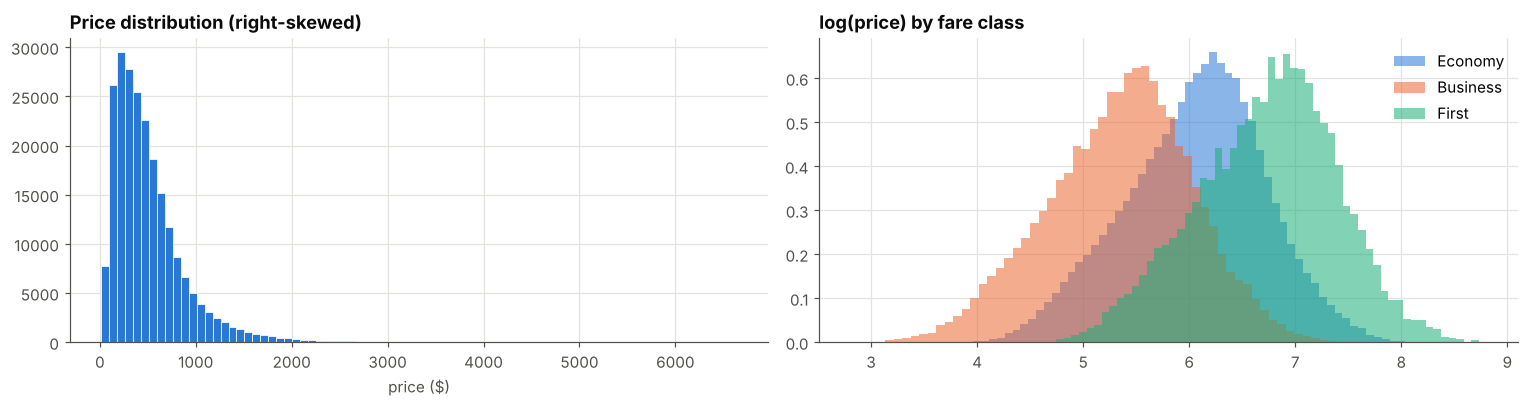

,count,mean,std,min,25%,50%,75%,max
fare_class,,,,,,,,
Business,"33,960.00",260.76,181.98,16.61,133.58,219.44,333.32,"2,067.85"
Economy,"179,867.00",523.81,348.43,42.18,277.23,448.59,669.85,"3,586.14"
First,"11,382.00","1,029.01",686.55,93.07,536.57,883.78,"1,323.62","6,639.68"


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
axes[0].hist(d.price, bins=80, color=C1, edgecolor='white', linewidth=0.5)
axes[0].set_title('Price distribution (right-skewed)'); axes[0].set_xlabel('price ($)')
for fc in ['Economy', 'Business', 'First']:
    axes[1].hist(np.log(d.loc[d.fare_class == fc, 'price']), bins=60, alpha=0.55,
                 color=FARE_COLORS[fc], label=fc, density=True)
axes[1].set_title('log(price) by fare class'); axes[1].legend(frameon=False)
plt.tight_layout(); plt.show()
d.groupby('fare_class').price.describe()

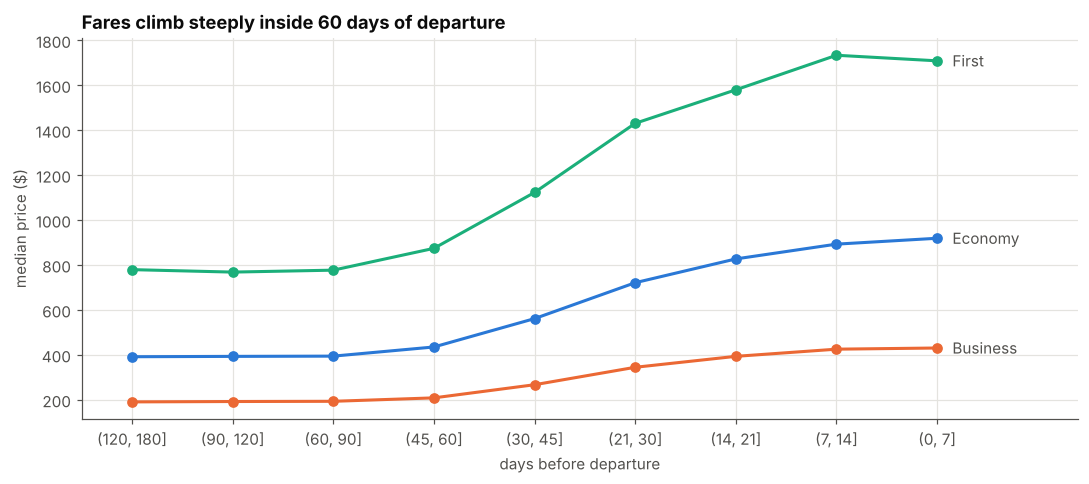

fare_class,Business,Economy,First
lead_bucket,,,
"(0, 7]",430.59,919.19,"1,709.15"
"(7, 14]",425.38,892.98,"1,733.93"
"(14, 21]",393.44,827.17,"1,580.06"
"(21, 30]",344.74,721.28,"1,430.87"
"(30, 45]",267.06,561.41,"1,123.06"
"(45, 60]",208.56,435.15,874.24
"(60, 90]",193.23,394.37,777.13
"(90, 120]",192.30,393.25,768.55
"(120, 180]",190.65,391.73,779.49


In [7]:
# The key relationship for the feature: price vs days before departure
d['lead_bucket'] = pd.cut(d.days_before, [0, 7, 14, 21, 30, 45, 60, 90, 120, 180])
curve = d.groupby(['lead_bucket', 'fare_class'], observed=True).price.median().unstack()

fig, ax = plt.subplots()
for fc in ['First', 'Economy', 'Business']:
    ax.plot(range(len(curve)), curve[fc], marker='o', markersize=6, color=FARE_COLORS[fc])
    ax.annotate(fc, (0, curve[fc].iloc[0]), xytext=(10, 0),
                textcoords='offset points', va='center', color=INK2)
ax.set_xticks(range(len(curve))); ax.set_xticklabels([str(b) for b in curve.index], rotation=0)
ax.set_xlabel('days before departure'); ax.set_ylabel('median price ($)')
ax.set_title('Fares climb steeply inside 60 days of departure')
ax.set_xlim(len(curve) - 0.5, -1.4); plt.tight_layout(); plt.show()
curve

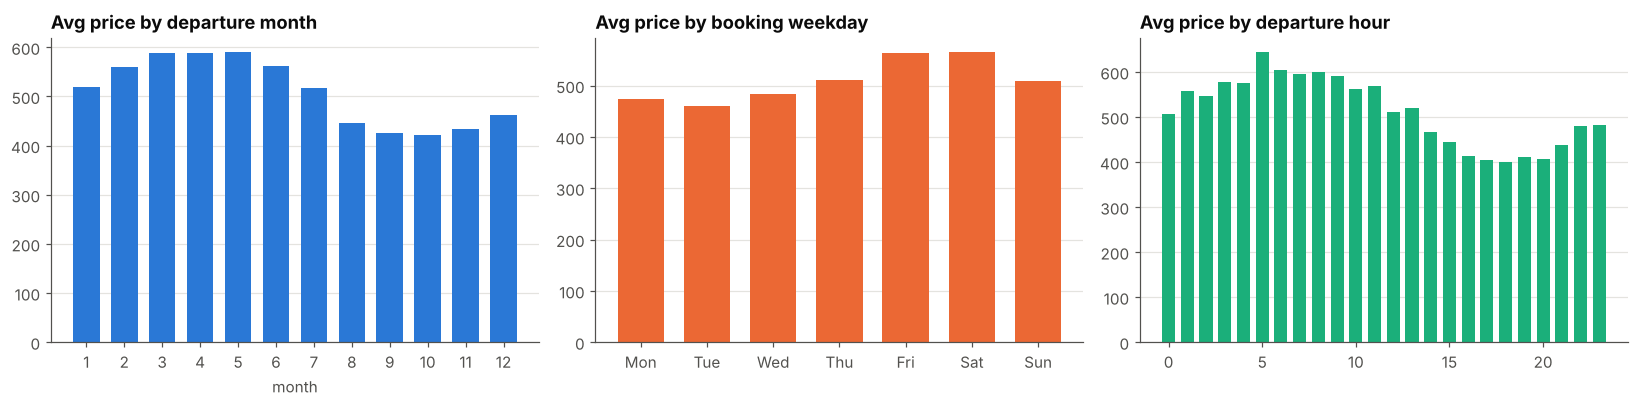

Average price by route ($):


destination,BOS,DEN,DFW,MIA,SEA
origin,,,,,
ATL,405.00,438.00,503.00,663.00,536.00
JFK,389.00,436.00,495.00,650.00,552.00
LAX,413.00,467.00,485.00,636.00,557.00
ORD,411.00,459.00,471.00,674.00,530.00
SFO,398.00,454.00,500.00,670.00,582.00


Average price by departure year ($):


departure_dt
2022   467.00
2023   507.00
2024   556.00
Name: price, dtype: float64

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
m = d.groupby(d.departure_dt.dt.month).price.mean()
axes[0].bar(m.index, m.values, color=C1, width=0.7); axes[0].set_xticks(range(1, 13))
axes[0].set_title('Avg price by departure month'); axes[0].set_xlabel('month')
days = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
b = d.groupby(d.booking_dt.dt.dayofweek).price.mean()
axes[1].bar(days, b.values, color=C2, width=0.7); axes[1].set_title('Avg price by booking weekday')
h = d.groupby(d.departure_dt.dt.hour).price.mean()
axes[2].bar(h.index, h.values, color=C3, width=0.7); axes[2].set_title('Avg price by departure hour')
for ax in axes: ax.grid(axis='x', visible=False)
plt.tight_layout(); plt.show()

route = d.groupby(['origin', 'destination']).price.mean().unstack()
print("Average price by route ($):"); display(route.round(0))
print("Average price by departure year ($):"); display(d.groupby(d.departure_dt.dt.year).price.mean().round(0))

**What drives price (insights for feature engineering)**

1. **Lead time is the dominant factor.** Prices are flat from 180 down to about 60 days out, then roughly double inside the last 30 days. For travellers: book at least two months ahead.
2. **Seasonality:** February to June departures are the most expensive (spring and early summer peak); August to November are cheapest.
3. **Booking weekday matters:** booking on a Friday or Saturday costs around 15 to 20% more than booking on a Monday or Tuesday. This is the lever the "Interactive Calendar" can exploit inside a one-week window.
4. **Departure time:** early morning departures (5 to 9am) cost about 50% more than late-afternoon ones.
5. **Destination:** Miami is the priciest destination and Boston the cheapest. The origin and airline barely matter.
6. **Prices rise about 9% a year** (2022 to 2024).
7. **Noise is large.** The same flight booked a few hours apart can cost $660 or $1,190 (see below), so individual tickets are hard to predict, but averages are very stable. The model should be judged on how well it recovers the expected price curve.

In [9]:
# How noisy are individual prices? Same flight, same fare class, same week of booking
d['lead_week'] = d.days_before // 7
cell = d.groupby(['flight_id', 'fare_class', 'lead_week']).price
cv = (cell.std() / cell.mean()).dropna()
print(f"Median coefficient of variation within flight x fare x booking-week: {cv.median():.0%}")

Median coefficient of variation within flight x fare x booking-week: 42%


## Data Preparation

## Format Fields

In [10]:
df = df_booking.copy()
df['booking_dt'] = pd.to_datetime(df['booking_dt'])
df['departure_dt'] = pd.to_datetime(df['departure_dt'])

CAT_COLS = ['airline', 'origin', 'destination', 'fare_class']
encoders = {}
for col in CAT_COLS:
    df[col] = df[col].astype('category')
    encoders[col] = LabelEncoder().fit(df[col].astype(str))
    df[col + '_enc'] = encoders[col].transform(df[col].astype(str))

df = df.sort_values('booking_dt').reset_index(drop=True)
df.dtypes

transaction_id                str
flight_id                     str
airline                  category
origin                   category
destination              category
booking_dt         datetime64[us]
departure_dt       datetime64[us]
price                     float64
fare_class               category
airline_enc                 int64
origin_enc                  int64
destination_enc             int64
fare_class_enc              int64
dtype: object

## Split Data

In [11]:
# Chronological split on departure date, so we always predict flights that are "in the future"
TRAIN_END, VALID_END = '2023-10-01', '2024-03-01'
is_train = df.departure_dt < TRAIN_END
is_valid = (df.departure_dt >= TRAIN_END) & (df.departure_dt < VALID_END)
is_test = df.departure_dt >= VALID_END

for name, mask in [('train', is_train), ('valid', is_valid), ('test', is_test)]:
    part = df[mask]
    print(f"{name:5s}: {mask.sum():>7,} rows  ({mask.mean():.0%})  departures "
          f"{part.departure_dt.min().date()} to {part.departure_dt.max().date()}")

train: 140,420 rows  (62%)  departures 2022-04-09 to 2023-09-30
valid:  46,599 rows  (21%)  departures 2023-10-01 to 2024-02-29
test :  38,190 rows  (17%)  departures 2024-03-01 to 2024-09-15


## Feature Engineering

## Compute Delta

In [12]:
def add_features(frame):
    """Build model features from booking / departure timestamps. Used for training AND scenario planning."""
    out = frame.copy()
    delta = out['departure_dt'] - out['booking_dt']
    out['days_before'] = delta.dt.total_seconds() / 86400         # continuous lead time in days
    out['weeks_before'] = (out['days_before'] // 7).astype(int)
    out['last_minute'] = (out['days_before'] <= 14).astype(int)

    # booking timestamp
    out['book_dow'] = out['booking_dt'].dt.dayofweek
    out['book_weekend'] = out['book_dow'].isin([4, 5]).astype(int)  # Fri/Sat booking
    out['book_hour'] = out['booking_dt'].dt.hour
    out['book_month'] = out['booking_dt'].dt.month
    out['book_day'] = out['booking_dt'].dt.day

    # departure timestamp
    out['dep_year'] = out['departure_dt'].dt.year
    out['dep_month'] = out['departure_dt'].dt.month
    out['dep_day'] = out['departure_dt'].dt.day
    out['dep_dow'] = out['departure_dt'].dt.dayofweek
    out['dep_doy'] = out['departure_dt'].dt.dayofyear
    out['dep_hour'] = out['departure_dt'].dt.hour
    out['dep_weekend'] = out['dep_dow'].isin([5, 6]).astype(int)
    return out

df = add_features(df)
df[['booking_dt', 'departure_dt', 'days_before', 'weeks_before', 'last_minute']].head()

,booking_dt,departure_dt,days_before,weeks_before,last_minute
0,2021-10-12 11:58:26,2022-04-09 04:12:00,178.68,25,0
1,2021-10-16 10:49:41,2022-04-13 12:09:00,179.06,25,0
2,2021-10-16 21:53:41,2022-04-09 04:12:00,174.26,24,0
3,2021-10-16 23:30:52,2022-04-14 21:33:00,179.92,25,0
4,2021-10-17 20:39:34,2022-04-14 21:33:00,179.04,25,0


## Decompose TS

In [13]:
TS_FEATURES = ['book_dow', 'book_weekend', 'book_hour', 'book_month', 'book_day',
               'dep_year', 'dep_month', 'dep_day', 'dep_dow', 'dep_doy', 'dep_hour', 'dep_weekend']
df[['booking_dt', 'departure_dt'] + TS_FEATURES].head()

,booking_dt,departure_dt,book_dow,book_weekend,book_hour,book_month,book_day,dep_year,dep_month,dep_day,dep_dow,dep_doy,dep_hour,dep_weekend
0,2021-10-12 11:58:26,2022-04-09 04:12:00,1,0,11,10,12,2022,4,9,5,99,4,1
1,2021-10-16 10:49:41,2022-04-13 12:09:00,5,1,10,10,16,2022,4,13,2,103,12,0
2,2021-10-16 21:53:41,2022-04-09 04:12:00,5,1,21,10,16,2022,4,9,5,99,4,1
3,2021-10-16 23:30:52,2022-04-14 21:33:00,5,1,23,10,16,2022,4,14,3,104,21,0
4,2021-10-17 20:39:34,2022-04-14 21:33:00,6,0,20,10,17,2022,4,14,3,104,21,0


## Feature Selection

## RF Feature Selection

In [14]:
CANDIDATES = ['days_before', 'weeks_before', 'last_minute'] + TS_FEATURES + [c + '_enc' for c in CAT_COLS]
TARGET = 'price'

train_df, valid_df, test_df = df[is_train], df[is_valid], df[is_test]

# Random forest on a sample of the training set (fast, and plenty for ranking features)
rf_sample = train_df.sample(40_000, random_state=SEED)
rf = RandomForestRegressor(n_estimators=150, max_depth=14, min_samples_leaf=20,
                           n_jobs=-1, random_state=SEED)
rf.fit(rf_sample[CANDIDATES], np.log(rf_sample[TARGET]))
importance = pd.Series(rf.feature_importances_, index=CANDIDATES).sort_values(ascending=False)
importance

fare_class_enc    0.33
days_before       0.30
destination_enc   0.09
dep_hour          0.08
dep_doy           0.07
book_dow          0.02
dep_dow           0.02
book_day          0.02
book_hour         0.02
dep_day           0.01
book_weekend      0.01
book_month        0.01
origin_enc        0.01
airline_enc       0.01
dep_month         0.00
dep_weekend       0.00
weeks_before      0.00
dep_year          0.00
last_minute       0.00
dtype: float64

## Feature Importance

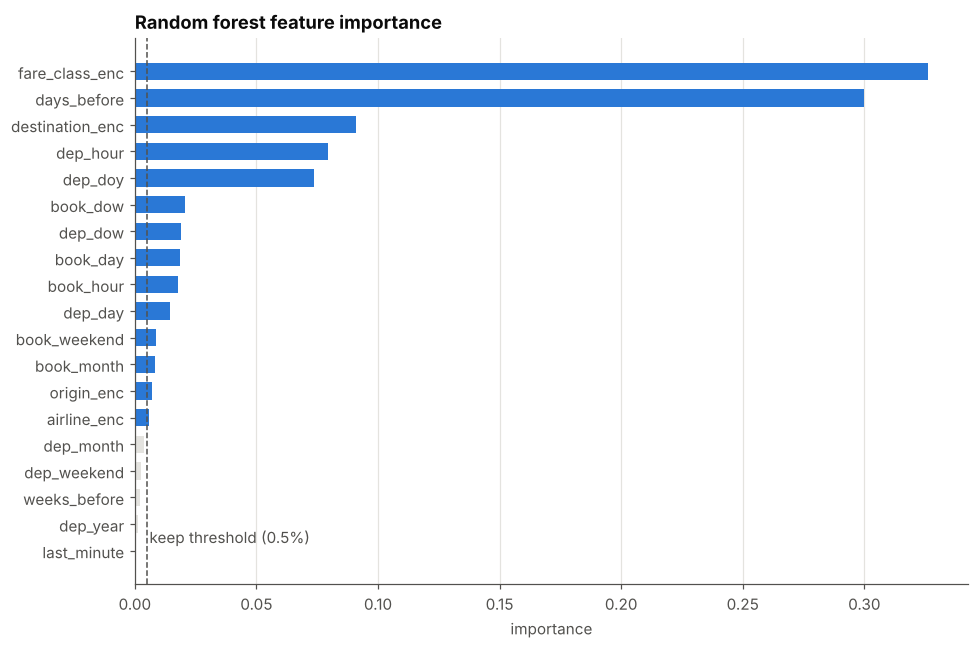

In [15]:
imp = importance.sort_values()
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(imp.index, imp.values, color=[C1 if v >= 0.005 else GRID for v in imp.values], height=0.65)
ax.axvline(0.005, color=INK2, linestyle='--', linewidth=1)
ax.text(0.006, 0.5, 'keep threshold (0.5%)', color=INK2, va='center')
ax.set_title('Random forest feature importance'); ax.set_xlabel('importance')
ax.grid(axis='y', visible=False); plt.tight_layout(); plt.show()

## Filter Columns

In [16]:
# Keep features above 0.5% importance; always keep the business inputs a user selects in the calendar
MUST_KEEP = ['days_before', 'book_dow', 'airline_enc', 'origin_enc', 'destination_enc', 'fare_class_enc']
FEATURES = sorted(set(importance[importance >= 0.005].index) | set(MUST_KEEP), key=CANDIDATES.index)
# dep_year lets trees memorise a level per year but cannot extrapolate to future years; we drop it
FEATURES = [f for f in FEATURES if f != 'dep_year']
print(len(FEATURES), 'features kept:', FEATURES)

X_train, y_train = train_df[FEATURES], train_df[TARGET]
X_valid, y_valid = valid_df[FEATURES], valid_df[TARGET]
X_test, y_test = test_df[FEATURES], test_df[TARGET]

14 features kept: ['days_before', 'book_dow', 'book_weekend', 'book_hour', 'book_month', 'book_day', 'dep_day', 'dep_dow', 'dep_doy', 'dep_hour', 'airline_enc', 'origin_enc', 'destination_enc', 'fare_class_enc']


## Model Selection

## Baseline Model

In [17]:
def evaluate(y_true, y_pred, name=''):
    return pd.Series({
        'MAPE': mean_absolute_percentage_error(y_true, y_pred),
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'R2': r2_score(y_true, y_pred),
    }, name=name)

# Train on log(price): fares are multiplicative (fare class x lead time x season)
baseline = xgb.XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=6,
                            tree_method='hist', random_state=SEED)
baseline.fit(X_train, np.log(y_train))
pred_valid_base = np.exp(baseline.predict(X_valid))
evaluate(y_valid, pred_valid_base, 'XGB baseline (valid)').to_frame().T

,MAPE,MAE,RMSE,R2
XGB baseline (valid),0.51,188.19,256.71,0.50


## Hyperparameter Tuning

In [18]:
param_dist = {
    'n_estimators': [300, 500, 800, 1200],
    'learning_rate': [0.02, 0.03, 0.05, 0.1],
    'max_depth': [4, 5, 6, 7, 8],
    'min_child_weight': [1, 5, 20, 50],
    'subsample': [0.7, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'reg_lambda': [0.5, 1, 5, 10],
}
results = []
for i, params in enumerate(ParameterSampler(param_dist, n_iter=15, random_state=SEED)):
    m = xgb.XGBRegressor(tree_method='hist', random_state=SEED, **params)
    m.fit(X_train, np.log(y_train))
    p = np.exp(m.predict(X_valid))
    results.append({**params, **evaluate(y_valid, p).to_dict()})

tuning = pd.DataFrame(results).sort_values('RMSE')
tuning.head(5)

,subsample,reg_lambda,n_estimators,min_child_weight,max_depth,learning_rate,colsample_bytree,MAPE,MAE,RMSE,R2
6,0.80,0.50,300,20,4,0.05,0.80,0.51,187.18,254.38,0.51
3,1.00,10.00,800,5,4,0.02,1.00,0.51,187.17,254.53,0.51
10,0.70,1.00,500,20,5,0.02,0.80,0.51,187.31,254.93,0.51
9,1.00,0.50,500,5,4,0.10,0.80,0.51,187.66,255.01,0.51
11,1.00,1.00,1200,20,5,0.02,0.80,0.51,187.52,255.04,0.51


In [19]:
best_params = {k: (int(v) if k in ('n_estimators', 'max_depth', 'min_child_weight') else v)
               for k, v in tuning.iloc[0][list(param_dist)].items()}
print('Best params:', best_params)

# Refit on train + valid so the final model has seen the most recent prices
X_trval = pd.concat([X_train, X_valid]); y_trval = pd.concat([y_train, y_valid])
model = xgb.XGBRegressor(tree_method='hist', random_state=SEED, **best_params)
model.fit(X_trval, np.log(y_trval))

# Log-model predicts the median; a smearing factor converts to the expected (mean) price in dollars
SMEAR = np.mean(np.exp(np.log(y_trval) - model.predict(X_trval)))
print(f'Smearing factor: {SMEAR:.3f}')

# Quantile models give the low/high price band shown to users (25th to 75th percentile)
band = xgb.XGBRegressor(tree_method='hist', random_state=SEED, objective='reg:quantileerror',
                        quantile_alpha=np.array([0.25, 0.75]),
                        **{k: v for k, v in best_params.items()})
band.fit(X_trval, y_trval)

Best params: {'n_estimators': 300, 'learning_rate': 0.05, 'max_depth': 4, 'min_child_weight': 20, 'subsample': 0.8, 'colsample_bytree': 0.8, 'reg_lambda': 0.5}


Smearing factor: 1.129


,"objective objective: typing.Union[str, xgboost.objective.Objective, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'reg:quantileerror'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from skle

## Model Evaluation

## Evaluation Dataset

In [20]:
eval_df = test_df[['flight_id', 'airline', 'origin', 'destination', 'fare_class',
                   'booking_dt', 'departure_dt', 'days_before', 'price']].copy()
eval_df['pred_median'] = np.exp(model.predict(X_test))
eval_df['pred_mean'] = eval_df['pred_median'] * SMEAR
q = band.predict(X_test)
eval_df['p25'], eval_df['p75'] = q[:, 0], q[:, 1]
print(f"Test set: {len(eval_df):,} bookings on flights departing {eval_df.departure_dt.min().date()} "
      f"to {eval_df.departure_dt.max().date()}")
print(f"Share of actual prices inside the predicted 25-75% band: "
      f"{((eval_df.price >= eval_df.p25) & (eval_df.price <= eval_df.p75)).mean():.0%} (target 50%)")
eval_df.head()

Test set: 38,190 bookings on flights departing 2024-03-01 to 2024-09-15
Share of actual prices inside the predicted 25-75% band: 47% (target 50%)


,flight_id,airline,origin,destination,fare_class,booking_dt,departure_dt,days_before,price,pred_median,pred_mean,p25,p75
159867,1fb187,Delta Air Lines,JFK,DEN,Economy,2023-09-04 02:25:49,2024-03-01 21:29:00,179.79,357.81,276.93,312.56,207.13,457.19
160109,b982ab,American Airlines,JFK,DFW,First,2023-09-04 19:08:11,2024-03-02 07:09:00,179.50,"1,268.95",824.90,931.04,531.56,"1,077.92"
160128,b81301,Delta Air Lines,JFK,DEN,Business,2023-09-04 21:16:44,2024-03-02 01:05:00,179.16,272.24,169.86,191.71,123.23,278.33
160206,66a1c4,Delta Air Lines,ATL,MIA,Economy,2023-09-05 03:06:51,2024-03-02 01:11:00,178.92,932.67,478.79,540.39,340.96,726.72
160243,b81301,Delta Air Lines,JFK,DEN,Economy,2023-09-05 06:16:57,2024-03-02 01:05:00,178.78,551.10,339.49,383.17,253.37,556.65


## Business Method


In [21]:
# Business method: the rule an analyst would use without ML.
# Median historical price for the same route x fare class x weeks-before-departure.
key = ['origin', 'destination', 'fare_class', 'weeks_before']
hist = pd.concat([train_df, valid_df])
lookup = hist.groupby(key, observed=True).price.median().rename('pred_business').reset_index()
fallback = hist.groupby(['fare_class', 'weeks_before'], observed=True).price.median().rename('fb').reset_index()

tmp = test_df[key].merge(lookup, on=key, how='left').merge(fallback, on=['fare_class', 'weeks_before'], how='left')
eval_df['pred_business'] = tmp['pred_business'].fillna(tmp['fb']).values

overall = pd.DataFrame([
    evaluate(eval_df.price, eval_df.pred_business, 'Business method (route x fare x week median)'),
    evaluate(eval_df.price, eval_df.pred_median, 'XGBoost (median)'),
    evaluate(eval_df.price, eval_df.pred_mean, 'XGBoost (mean, smeared)'),
])
overall

,MAPE,MAE,RMSE,R2
Business method (route x fare x week median),0.53,235.85,330.17,0.38
XGBoost (median),0.51,218.89,295.72,0.50
"XGBoost (mean, smeared)",0.57,214.30,285.33,0.54


In [22]:
# Simpson's paradox check: is ML better in every fare class, not just overall?
rows = []
for fc, g in eval_df.groupby('fare_class', observed=True):
    for name, col in [('Business method', 'pred_business'), ('XGBoost', 'pred_median')]:
        rows.append({'fare_class': fc, 'method': name, 'n': len(g), **evaluate(g.price, g[col]).to_dict()})
by_class = pd.DataFrame(rows).set_index(['fare_class', 'method'])
display(by_class)

rows = []
for (lw, g) in eval_df.groupby(pd.cut(eval_df.days_before, [0, 14, 30, 60, 90, 180]), observed=True):
    rows.append({'days_before': str(lw),
                 'business_MAPE': mean_absolute_percentage_error(g.price, g.pred_business),
                 'xgb_MAPE': mean_absolute_percentage_error(g.price, g.pred_median)})
display(pd.DataFrame(rows))

n  MAPE    MAE   RMSE   R2
fare_class method                                         
Business   Business method   5719  0.56 127.54 176.18 0.21
           XGBoost           5719  0.54 117.94 158.45 0.36
Economy    Business method  30516  0.53 239.71 320.69 0.29
           XGBoost          30516  0.51 223.60 289.47 0.42
First      Business method   1955  0.56 492.47 658.35 0.19
           XGBoost           1955  0.51 440.71 571.71 0.39

,days_before,business_MAPE,xgb_MAPE
0,"(0, 14]",0.54,0.51
1,"(14, 30]",0.52,0.50
2,"(30, 60]",0.54,0.52
3,"(60, 90]",0.54,0.51
4,"(90, 180]",0.53,0.51


,MAPE,MAE,RMSE,R2
Business method,0.25,146.75,205.05,0.51
XGBoost,0.20,101.49,140.53,0.77


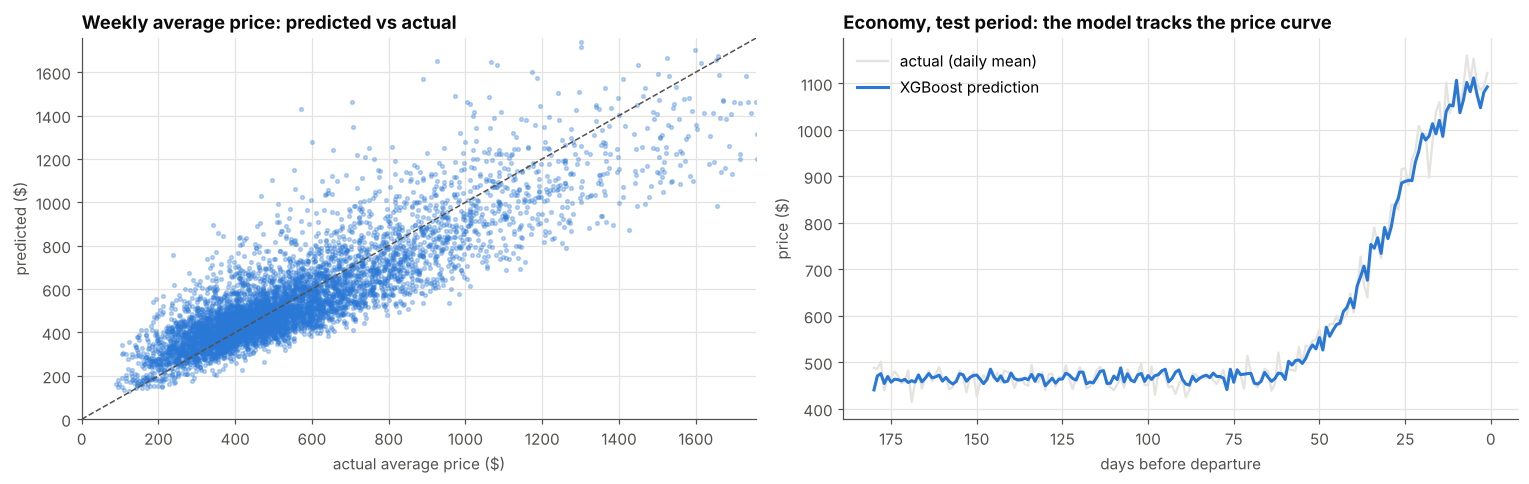

In [23]:
# Because single tickets are so noisy, also check how well the model recovers the AVERAGE price:
# average actual vs predicted per flight x fare class x booking week (what the calendar shows)
agg = eval_df.assign(week=(eval_df.days_before // 7)).groupby(
    ['flight_id', 'fare_class', 'week'], observed=True).agg(
    actual=('price', 'mean'), xgb=('pred_mean', 'mean'), business=('pred_business', 'mean'), n=('price', 'size'))
agg = agg[agg.n >= 3]
display(pd.DataFrame([evaluate(agg.actual, agg.business, 'Business method'),
                      evaluate(agg.actual, agg.xgb, 'XGBoost')]))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
lim = agg[['actual', 'xgb']].quantile(0.995).max()
axes[0].scatter(agg.actual, agg.xgb, s=6, alpha=0.3, color=C1)
axes[0].plot([0, lim], [0, lim], color=INK2, linewidth=1, linestyle='--')
axes[0].set_xlim(0, lim); axes[0].set_ylim(0, lim)
axes[0].set_xlabel('actual average price ($)'); axes[0].set_ylabel('predicted ($)')
axes[0].set_title('Weekly average price: predicted vs actual')

c = eval_df.groupby([eval_df.days_before.round().astype(int), 'fare_class'], observed=True)[['price', 'pred_mean']].mean().unstack()
for fc in ['Economy']:
    axes[1].plot(c.index, c['price'][fc], color=GRID, linewidth=1.5, label='actual (daily mean)')
    axes[1].plot(c.index, c['pred_mean'][fc], color=C1, label='XGBoost prediction')
axes[1].invert_xaxis(); axes[1].legend(frameon=False)
axes[1].set_xlabel('days before departure'); axes[1].set_ylabel('price ($)')
axes[1].set_title('Economy, test period: the model tracks the price curve')
plt.tight_layout(); plt.show()

**Evaluation summary**

- Individual ticket prices carry about 40% random noise (the same flight, fare and week varies that much), so no model gets a single-ticket MAPE near zero. On single 2024 test tickets XGBoost scores MAPE 51% / R² 0.50 against 53% / 0.38 for the business rule, and cuts RMSE from \$330 to \$296.
- XGBoost (median prediction) beats the business rule on every metric overall, in every fare class and in every lead-time bucket, so there is no Simpson's paradox: the gain is not driven by one subgroup. (The "smeared" mean version trades a worse MAPE for lower dollar error; we use it for dollar savings in the calendar.)
- What the calendar needs is the expected price for a booking day. At that level (weekly averages per flight) XGBoost reaches MAPE 20% and R² 0.77, versus 25% and 0.51 for the business rule, and it follows the real price curve closely in the held-out 2024 period.
- The business rule cannot capture booking weekday, departure hour or seasonality, which are exactly the levers the scenario tool needs. That is the practical case for ML here.

## Scenario Planning: Best Day to Book

## Scenario Tool

In [24]:
def predict_booking_calendar(today_date, departure_date, airline, origin, destination, fare_class,
                             window_days=7, departure_time='08:00'):
    """Predict expected price and a 25-75% range for each possible booking date
    from today_date up to window_days ahead (never on or after departure)."""
    today = pd.Timestamp(today_date)
    dep = pd.Timestamp(f'{departure_date} {departure_time}')
    last = min(today + pd.Timedelta(days=window_days - 1), dep.normalize() - pd.Timedelta(days=1))
    book_days = pd.date_range(today, last, freq='D')
    # Price changes during the day are noise; average over hours 8am to 8pm for each booking day
    grid = pd.DataFrame([(b + pd.Timedelta(hours=h)) for b in book_days for h in range(8, 21)],
                        columns=['booking_dt'])
    grid['departure_dt'] = dep
    grid['airline'], grid['origin'], grid['destination'], grid['fare_class'] = airline, origin, destination, fare_class
    for col in CAT_COLS:
        grid[col + '_enc'] = encoders[col].transform(grid[col])
    grid = add_features(grid)
    X = grid[FEATURES]
    grid['expected'] = np.exp(model.predict(X)) * SMEAR
    q = band.predict(X); grid['low'], grid['high'] = q[:, 0], q[:, 1]
    out = (grid.assign(booking_date=grid.booking_dt.dt.normalize())
               .groupby('booking_date')[['expected', 'low', 'high']].mean())
    out['days_before'] = (dep.normalize() - out.index).days
    out['weekday'] = out.index.day_name()
    out['vs_today'] = out['expected'] - out['expected'].iloc[0]
    return out


def plot_booking_calendar(cal, title):
    best = cal['expected'].idxmin()
    fig, ax = plt.subplots(figsize=(10, 4.5))
    x = np.arange(len(cal))
    ax.fill_between(x, cal['low'], cal['high'], color=C1, alpha=0.15, linewidth=0, label='typical range (25-75%)')
    ax.plot(x, cal['expected'], color=C1, marker='o', markersize=7, label='expected price')
    bi = cal.index.get_loc(best)
    ax.scatter([bi], [cal['expected'].iloc[bi]], s=160, color=C3, zorder=5, edgecolor='white', linewidth=2)
    save = cal['expected'].iloc[0] - cal['expected'].iloc[bi]
    ax.annotate(f"Best: {best:%a %b %d}\n\\${cal['expected'].iloc[bi]:,.0f}" + (f" (save \\${save:,.0f})" if save > 0.5 else ''),
                (bi, cal['expected'].iloc[bi]), xytext=(0, -42), textcoords='offset points',
                ha='center', color=INK, fontweight='bold')
    ax.annotate(f"Today \\${cal['expected'].iloc[0]:,.0f}", (0, cal['expected'].iloc[0]),
                xytext=(0, 12), textcoords='offset points', ha='center', color=INK2)
    ax.set_xticks(x); ax.set_xticklabels([f'{d:%a}\n{d:%b %d}' for d in cal.index])
    ax.set_ylabel('price ($)'); ax.set_title(title); ax.legend(frameon=False, loc='upper left')
    ax.set_ylim(min(cal['low'].min(), cal['expected'].min() - 60) * 0.9, cal['high'].max() * 1.08)
    plt.tight_layout(); plt.show()


def booking_advice(cal):
    best = cal['expected'].idxmin(); worst = cal['expected'].idxmax()
    today_price = cal['expected'].iloc[0]
    save = today_price - cal.loc[best, 'expected']
    if save < 1:
        return f"Book today ({cal.index[0]:%a %b %d}) at about ${today_price:,.0f}: no day in the window is cheaper."
    return (f"Wait and book on {best:%A %b %d} for about ${cal.loc[best, 'expected']:,.0f}, "
            f"saving ~${save:,.0f} ({save / today_price:.0%}) vs booking today. "
            f"Avoid {worst:%A %b %d} (~${cal.loc[worst, 'expected']:,.0f}).")

## Example: JFK to MIA, searching Nov 1 for a Dec 1 departure

,expected,low,high,days_before,weekday,vs_today
booking_date,,,,,,
2024-11-01 00:00:00,$973,$473,"$1,061",30,Friday,+0
2024-11-02 00:00:00,$985,$479,"$1,078",29,Saturday,+12
2024-11-03 00:00:00,$948,$489,"$1,080",28,Sunday,-24
2024-11-04 00:00:00,$904,$489,"$1,085",27,Monday,-69
2024-11-05 00:00:00,$918,$492,"$1,107",26,Tuesday,-55
2024-11-06 00:00:00,$956,$504,"$1,119",25,Wednesday,-17
2024-11-07 00:00:00,"$1,039",$519,"$1,128",24,Thursday,+67


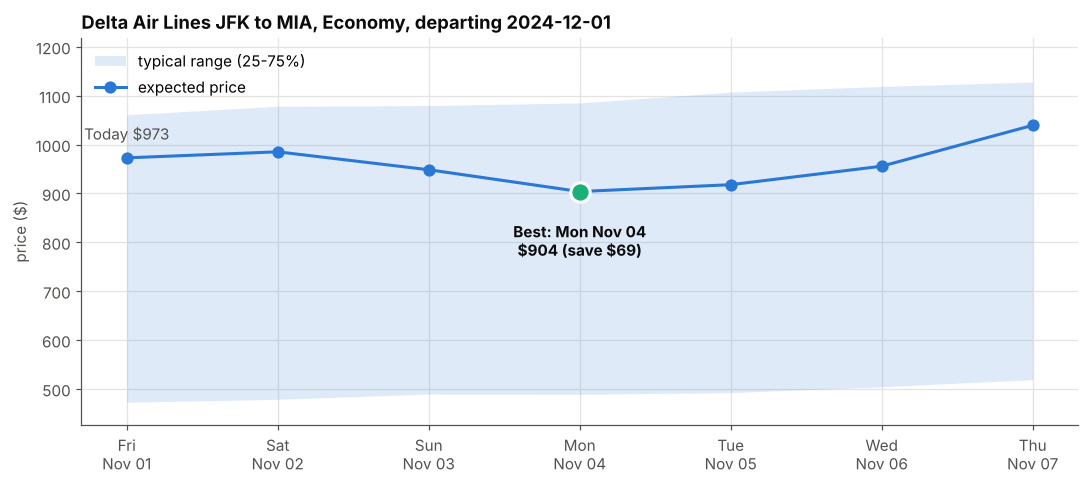

Wait and book on Monday Nov 04 for about $904, saving ~$69 (7%) vs booking today. Avoid Thursday Nov 07 (~$1,039).


In [25]:
# The boilerplate's JFK to LAX route is not in the data (LAX is only an origin), so we use JFK to MIA.
today_date = '2024-11-01'
departure_date = '2024-12-01'
airline = 'Delta Air Lines'
origin = 'JFK'
destination = 'MIA'
fare_class = 'Economy'

if departure_date <= today_date:
    raise ValueError("Departure date must be greater than today's date.")

cal = predict_booking_calendar(today_date, departure_date, airline, origin, destination, fare_class)
display(cal.style.format({'expected': '${:,.0f}', 'low': '${:,.0f}', 'high': '${:,.0f}', 'vs_today': '{:+,.0f}'}))
plot_booking_calendar(cal, f'{airline} {origin} to {destination}, {fare_class}, departing {departure_date}')
print(booking_advice(cal))

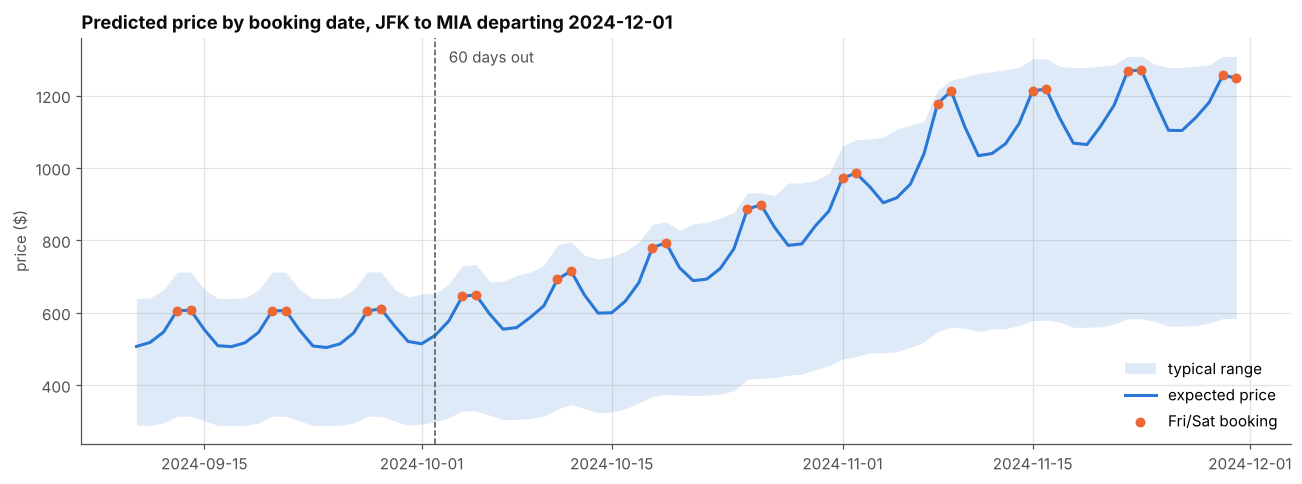

In [26]:
# The full "Interactive Calendar": every booking day from today until departure
full = predict_booking_calendar('2024-09-10', departure_date, airline, origin, destination, fare_class, window_days=82)
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.fill_between(full.index, full['low'], full['high'], color=C1, alpha=0.15, linewidth=0, label='typical range')
ax.plot(full.index, full['expected'], color=C1, label='expected price')
wk = full[full.index.dayofweek.isin([4, 5])]
ax.scatter(wk.index, wk['expected'], color=C2, s=30, zorder=4, label='Fri/Sat booking')
ax.axvline(pd.Timestamp(departure_date) - pd.Timedelta(days=60), color=INK2, linestyle='--', linewidth=1)
ax.text(pd.Timestamp(departure_date) - pd.Timedelta(days=59), ax.get_ylim()[1] * 0.95, '60 days out', color=INK2)
ax.set_ylabel('price ($)'); ax.legend(frameon=False, loc='lower right')
ax.set_title(f'Predicted price by booking date, {origin} to {destination} departing {departure_date}')
plt.tight_layout(); plt.show()

## More Example Scenarios

In [27]:
# More scenarios: what a user could save by choosing the best day in the next 7 days
examples = [
    ('2024-11-22', '2024-12-08', 'United Airlines', 'JFK', 'SEA', 'Business'),
    ('2024-11-01', '2024-12-01', 'Delta Air Lines', 'JFK', 'MIA', 'Economy'),
    ('2024-05-01', '2024-06-15', 'American Airlines', 'ORD', 'DEN', 'Economy'),
    ('2024-06-10', '2024-06-28', 'Delta Air Lines', 'ATL', 'BOS', 'First'),
    ('2024-03-04', '2024-04-20', 'United Airlines', 'SFO', 'DFW', 'Economy'),
]
rows = []
for t, dep, al, o, de, fc in examples:
    c = predict_booking_calendar(t, dep, al, o, de, fc)
    best = c['expected'].idxmin()
    rows.append({'route': f'{o}-{de}', 'airline': al, 'fare': fc, 'search': t, 'depart': dep,
                 'price_today': c['expected'].iloc[0], 'best_day': f'{best:%a %b %d}',
                 'best_price': c.loc[best, 'expected'],
                 'saving_$': c['expected'].iloc[0] - c.loc[best, 'expected']})
scen = pd.DataFrame(rows)
scen['saving_%'] = scen['saving_$'] / scen['price_today']
scen.style.format({'price_today': '${:,.0f}', 'best_price': '${:,.0f}', 'saving_$': '${:,.0f}', 'saving_%': '{:.0%}'})

,route,airline,fare,search,depart,price_today,best_day,best_price,saving_$,saving_%
0,JFK-SEA,United Airlines,Business,2024-11-22,2024-12-08,$495,Tue Nov 26,$430,$65,13%
1,JFK-MIA,Delta Air Lines,Economy,2024-11-01,2024-12-01,$973,Mon Nov 04,$904,$69,7%
2,ORD-DEN,American Airlines,Economy,2024-05-01,2024-06-15,$540,Wed May 01,$540,$0,0%
3,ATL-BOS,Delta Air Lines,First,2024-06-10,2024-06-28,"$1,634",Mon Jun 10,"$1,634",$0,0%
4,SFO-DFW,United Airlines,Economy,2024-03-04,2024-04-20,$564,Mon Mar 04,$564,$0,0%


## Backtest: Do Users Actually Save?

In [28]:
# Backtest on real test-period bookings: if a traveller searching on day D had followed the
# calendar's advice (book on the predicted-cheapest day within D..D+6), how much would they save
# on average versus booking immediately?  Uses ACTUAL average prices per flight x fare x booking day.
daily = eval_df.assign(bday=eval_df.booking_dt.dt.normalize()).groupby(
    ['flight_id', 'fare_class', 'bday'], observed=True).agg(actual=('price', 'mean'), pred=('pred_mean', 'mean')).reset_index()
savings = []
for (fid, fc), g in daily.groupby(['flight_id', 'fare_class'], observed=True):
    g = g.set_index('bday').sort_index()
    for d0 in g.index[::3]:
        win = g.loc[d0:d0 + pd.Timedelta(days=6)]
        if len(win) < 4:
            continue
        chosen = win['pred'].idxmin()
        savings.append({'fare_class': fc, 'actual_today': win['actual'].iloc[0],
                        'actual_chosen': win.loc[chosen, 'actual'], 'avg_window': win['actual'].mean()})
bt = pd.DataFrame(savings)
bt['saving_vs_today'] = bt.actual_today - bt.actual_chosen
print(f"Searches simulated: {len(bt):,}")
print(f"Average saving from following the calendar vs booking on search day: ${bt.saving_vs_today.mean():,.0f} "
      f"({bt.saving_vs_today.sum() / bt.actual_today.sum():.1%})")
print(f"Chosen day cheaper than a random day in the window in {(bt.actual_chosen < bt.avg_window).mean():.0%} of searches")
bt.groupby('fare_class')['saving_vs_today'].mean().rename('avg saving ($)').to_frame()

Searches simulated: 3,230
Average saving from following the calendar vs booking on search day: $31 (5.6%)
Chosen day cheaper than a random day in the window in 59% of searches


,avg saving ($)
fare_class,
Business,35.83
Economy,30.92


**Backtest result:** travellers who followed the calendar's pick within a 7-day window paid about \$31 (5.6%) less on average than booking on the day they searched. The chosen day beat a random day in the same window 59% of the time.